# Análisis exploratorio: redes sociales y productividad

## Objetivo
Explorar los patrones y relaciones presentes en el conjunto de datos,
formular cinco preguntas de análisis y responderlas mediante resúmenes
estadísticos, visualizaciones e interpretaciones.

## Estado de los datos
El diagnóstico inicial no identificó valores nulos, registros duplicados
ni inconsistencias evidentes en las variables examinadas. Por ello,
se utiliza el dataset original sin operaciones de limpieza adicionales.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

path = "/home/aivan/code/Entregables-BIT-IH/Entregas/social-media-productivity/data/raw/social_media_dopamine_productivity.csv"

df_raw = pd.read_csv(path, sep=",")
df = df_raw.copy()

print("Filas y columnas:", df.shape)
display(df.head())

Filas y columnas: (300, 66)


,participant_id,data_source,synthetic_flag,age,age_group,gender,race_ethnicity,nationality,country_of_residence,education_level,...,mood_dependency_on_sm,withdrawal_attempt_count,longest_detox_days,detox_relapse_reason,severity_stage,productivity_decline_score,dopamine_dysregulation_index,digital_wellbeing_score,sm_addiction_risk_score,notes
0,P0001,synthetic_ai,1,16,13-17,Female,South Asian,Indian,India,High school,...,Yes,9,2,3,Boredom,Critical,8.8,9.2,2.1,9.5
1,P0002,synthetic_ai,1,17,13-17,Male,East Asian,Chinese,China,High school,...,Yes,10,1,1,Curiosity,Critical,9.5,9.8,1.5,9.8
2,P0003,synthetic_ai,1,15,13-17,Female,Black/African,Nigerian,Nigeria,High school,...,Yes,8,2,5,Boredom,Severe,8.0,8.5,2.8,9.0
3,P0004,synthetic_ai,1,19,18-22,Male,White/Caucasian,American,USA,High school,...,Yes,9,3,7,Boredom,Severe,7.8,8.2,2.9,8.8
4,P0005,synthetic_ai,1,18,18-22,Female,Hispanic/Latino,Mexican,Mexico,High school,...,Yes,9,2,4,FOMO,Critical,9.0,9.3,2.0,9.6


In [2]:
print("Columnas disponibles:")
print(df.columns.tolist())

print("\nTipos de datos:")
display(df.dtypes.rename("tipo").to_frame())

print("\nResumen de variables numéricas:")
display(df.describe().T)

Columnas disponibles:
['participant_id', 'data_source', 'synthetic_flag', 'age', 'age_group', 'gender', 'race_ethnicity', 'nationality', 'country_of_residence', 'education_level', 'employment_status', 'occupation_category', 'relationship_status', 'avg_daily_sm_hours', 'years_on_social_media', 'primary_platform', 'secondary_platform', 'daily_check_frequency', 'first_check_of_day', 'late_night_scrolling', 'sm_during_work_study', 'sm_during_meals', 'notifications_always_on', 'scroll_without_purpose', 'doomscrolling_frequency', 'content_type_consumed', 'avg_daily_screen_time_hours', 'avg_sleep_hours', 'sleep_quality', 'exercise_frequency', 'avg_work_study_hours_per_day', 'dopamine_rush_feel_score', 'reward_seeking_behavior', 'fomo_score', 'comparison_to_others_score', 'validation_seeking_score', 'boredom_to_phone_reflex', 'inability_to_delay_gratification', 'attention_span_minutes', 'deep_work_duration_minutes', 'task_switching_frequency', 'difficulty_starting_tasks', 'difficulty_maintaini

,tipo
participant_id,str
data_source,str
synthetic_flag,int64
age,int64
age_group,str
...,...
productivity_decline_score,str
dopamine_dysregulation_index,float64
digital_wellbeing_score,float64
sm_addiction_risk_score,float64



Resumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
synthetic_flag,300.0,1.000000,0.000000,1.0,1.000,1.0,1.00,1.0
age,300.0,36.310000,15.175029,15.0,24.000,33.5,46.25,75.0
avg_daily_sm_hours,300.0,4.030000,2.034181,0.5,2.500,3.5,5.50,9.0
years_on_social_media,300.0,7.503333,2.690872,3.0,5.000,8.0,10.00,14.0
avg_daily_screen_time_hours,300.0,7.830000,2.271556,3.0,6.375,7.5,9.50,13.0
avg_sleep_hours,300.0,7.325000,1.033005,4.5,6.875,7.5,8.00,9.0
avg_work_study_hours_per_day,300.0,7.100000,2.673417,0.0,6.000,8.0,9.00,9.5
dopamine_rush_feel_score,300.0,4.920000,2.490168,1.0,3.000,4.0,7.00,10.0
reward_seeking_behavior,300.0,2.556667,1.308624,1.0,1.000,2.0,3.00,5.0
fomo_score,300.0,4.590000,2.142553,1.0,3.000,4.0,6.00,10.0


## Preguntas de análisis

1. ¿Cómo se distribuyen las horas diarias de uso de redes sociales?

2. ¿Qué relación existe entre las horas diarias de uso de redes sociales
   y la productividad autoevaluada?

3. ¿Cómo varía el tiempo promedio de uso de redes sociales según
   el grupo de edad?

4. ¿Qué relación existe entre las horas de sueño y la productividad
   autoevaluada?

5. ¿Cómo varían la cantidad promedio de tareas completadas y la
   productividad autoevaluada entre niveles de uso de redes sociales?

In [3]:
print("Fuente de los datos:")
print(df["data_source"].value_counts(dropna=False))

print("\nIndicador de datos sintéticos:")
print(df["synthetic_flag"].value_counts(dropna=False))

print("\nValores de productivity_decline_score:")
print(df["productivity_decline_score"].unique())

print("\nGrupos de edad:")
print(df["age_group"].value_counts(dropna=False))

Fuente de los datos:
data_source
synthetic_ai    300
Name: count, dtype: int64

Indicador de datos sintéticos:
synthetic_flag
1    300
Name: count, dtype: int64

Valores de productivity_decline_score:
<StringArray>
['Critical', 'Severe', 'Moderate', 'Early', 'None/Minimal']
Length: 5, dtype: str

Grupos de edad:
age_group
36-49    74
28-35    53
18-22    50
23-27    43
50-59    35
60+      27
13-17    18
Name: count, dtype: int64


## 1. Distribución del tiempo diario de uso de redes sociales

Se analiza la variable `avg_daily_sm_hours` para identificar
en qué intervalos se concentran los registros y cuánto varía
el tiempo de uso dentro del conjunto de datos sintético.

In [4]:
horas_redes = df["avg_daily_sm_hours"]

print(f"Registros: {horas_redes.count()}")
print(f"Promedio: {horas_redes.mean():.2f} horas")
print(f"Mediana: {horas_redes.median():.2f} horas")
print(f"Mínimo: {horas_redes.min():.2f} horas")
print(f"Máximo: {horas_redes.max():.2f} horas")

Registros: 300
Promedio: 4.03 horas
Mediana: 3.50 horas
Mínimo: 0.50 horas
Máximo: 9.00 horas


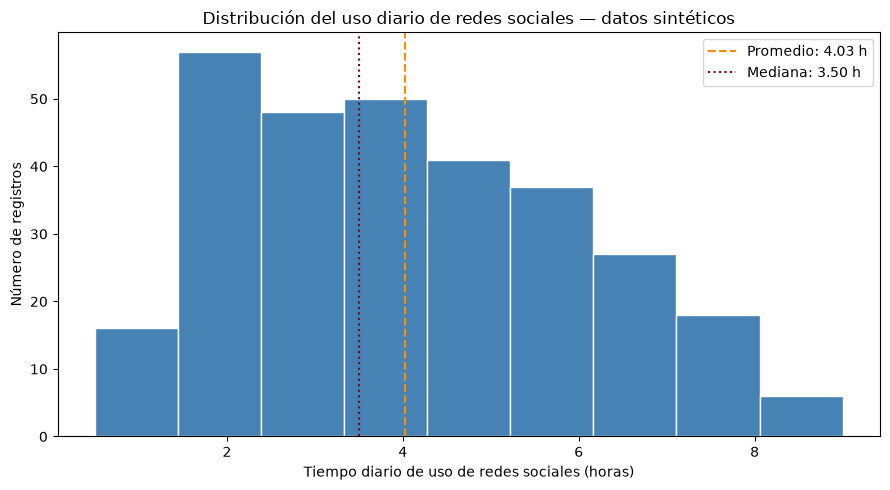

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    horas_redes,
    bins=9,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    horas_redes.mean(),
    color="darkorange",
    linestyle="--",
    label=f"Promedio: {horas_redes.mean():.2f} h"
)

plt.axvline(
    horas_redes.median(),
    color="darkred",
    linestyle=":",
    label=f"Mediana: {horas_redes.median():.2f} h"
)

plt.title("Distribución del uso diario de redes sociales — datos sintéticos")
plt.xlabel("Tiempo diario de uso de redes sociales (horas)")
plt.ylabel("Número de registros")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
horas_validas = df["avg_daily_sm_hours"].dropna()

cantidad_mayor_3 = (horas_validas > 3).sum()
porcentaje_mayor_3 = cantidad_mayor_3 / len(horas_validas) * 100

print(f"Registros con más de 3 horas: {cantidad_mayor_3}")
print(f"Porcentaje: {porcentaje_mayor_3:.2f}%")

Registros con más de 3 horas: 179
Porcentaje: 59.67%


En el conjunto de datos sintético, el tiempo diario de uso de redes sociales presenta un promedio de 4,03 horas y una mediana de 3,50 horas. El intervalo con mayor frecuencia se encuentra aproximadamente entre 1,4 y 2,4 horas. La distribución se extiende hacia valores altos de uso, por lo que el promedio supera a la mediana. Estos resultados muestran distintos niveles de uso dentro del conjunto, pero no permiten establecer todavía una relación con la productividad.

El 59.67% de los registros supera las 3 horas diarias de uso de redes sociales, equivalente a 179 de 300 registros.

## ¿Cómo varía el tiempo promedio de uso de redes sociales según el grupo de edad?

In [9]:

registros_por_edad = df.groupby("age_group").size()
print(registros_por_edad)

age_group
13-17    18
18-22    50
23-27    43
28-35    53
36-49    74
50-59    35
60+      27
dtype: int64


In [11]:
horas_por_edad = (
    df.groupby("age_group")["avg_daily_sm_hours"]
    .mean()
)

print(horas_por_edad)

age_group
13-17    7.444444
18-22    6.490000
23-27    4.930233
28-35    3.745283
36-49    3.256757
50-59    1.928571
60+      1.166667
Name: avg_daily_sm_hours, dtype: float64


In [12]:
resumen_por_edad = (
    df.groupby("age_group")["avg_daily_sm_hours"]
    .agg(["count", "mean", "mean"])
    .rename(columns ={
        "count" : "registros",
        "mean": "promedio_horas",
        "median": "mediana_horas"
    })
)

display(resumen_por_edad.round(2))

,registros,promedio_horas,promedio_horas
age_group,,,
13-17,18,7.44,7.44
18-22,50,6.49,6.49
23-27,43,4.93,4.93
28-35,53,3.75,3.75
36-49,74,3.26,3.26
50-59,35,1.93,1.93
60+,27,1.17,1.17


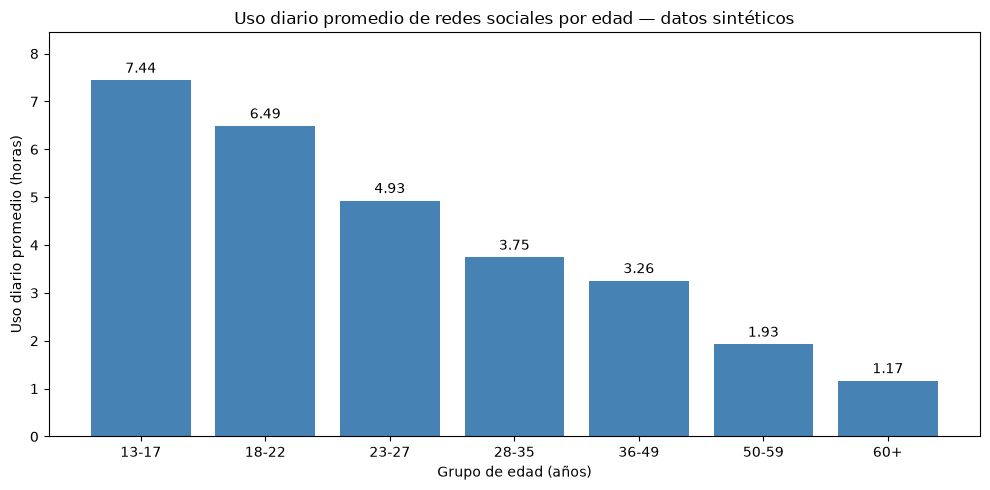

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    resumen_por_edad.index,
    resumen_por_edad["promedio_horas"],
    color="steelblue"
)

ax.bar_label(barras, fmt="%.2f", padding=3)

ax.set_title(
    "Uso diario promedio de redes sociales por edad — datos sintéticos"
)
ax.set_xlabel("Grupo de edad (años)")
ax.set_ylabel("Uso diario promedio (horas)")
ax.set_ylim(0, resumen_por_edad["promedio_horas"].max() + 1)

plt.tight_layout()
plt.show()

En el conjunto de datos sintético, el uso promedio diario de redes sociales disminuye progresivamente entre los grupos de edad. Los perfiles de 13 a 17 años presentan el promedio más alto, con 7,44 horas diarias, mientras que el grupo de 60 años o más registra el menor, con 1,17 horas. La diferencia entre ambos extremos es de aproximadamente 6,27 horas diarias. Este patrón describe un mayor tiempo de uso en los perfiles jóvenes del dataset, pero no permite concluir que envejecer cause una reducción del uso ni generalizar el resultado a personas reales.
image.jpg

## ¿Qué relación existe entre las horas diarias de uso de redes sociales y la productividad autoevaluada?

In [15]:
columnas = [
    "avg_daily_sm_hours",
    "productivity_self_rating"
]

datos_relacion = df[columnas].copy()
display(datos_relacion.head())
print("registros para el analisis", len(datos_relacion))

,avg_daily_sm_hours,productivity_self_rating
0,7.5,4
1,8.0,3
2,6.5,4
3,6.0,4
4,7.0,3


registros para el analisis 300


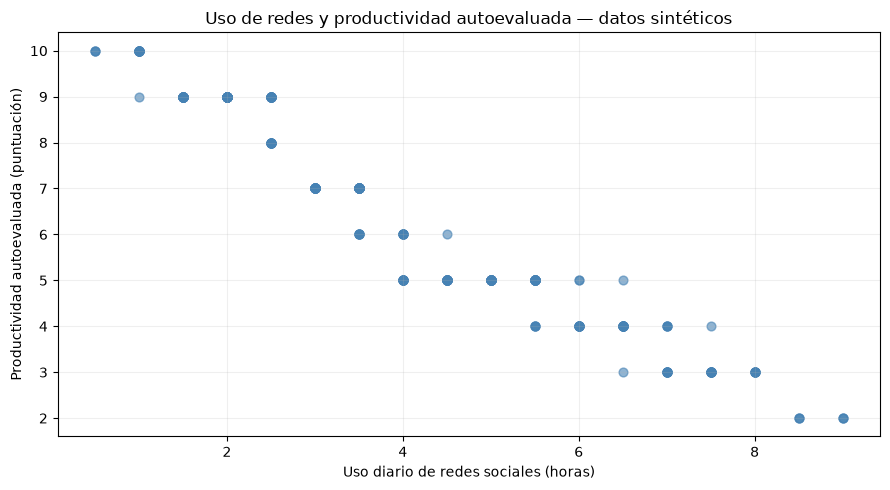

In [16]:
import matplotlib.pyplot as plt

x = datos_relacion["avg_daily_sm_hours"]
y = datos_relacion["productivity_self_rating"]

plt.figure(figsize=(9, 5))

plt.scatter(
    x,
    y,
    color="steelblue",
    alpha=0.6,
    s=40
)

plt.title("Uso de redes y productividad autoevaluada — datos sintéticos")
plt.xlabel("Uso diario de redes sociales (horas)")
plt.ylabel("Productividad autoevaluada (puntuación)")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()